## Code1 Damien
We first fetch the dataset and split it to 200 individuals

In [3]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

# 1. Fetch the dataset as a pandas DataFrame
housing = fetch_california_housing(as_frame=True)

# 2. Combine features (X) and target house value (y) into one DataFrame
df = housing.frame

# Display shape and first few rows
print(f"Sample shape: {df.shape}")
print(df.head())

Sample shape: (20640, 9)
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


### Quick Overview of the dataset

In [4]:
overview = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Count': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df)) * 100,
    'Unique Values': df.nunique()
})
print(overview)

            Data Type  Missing Count  Missing %  Unique Values
MedInc        float64              0        0.0          12928
HouseAge      float64              0        0.0             52
AveRooms      float64              0        0.0          19392
AveBedrms     float64              0        0.0          14233
Population    float64              0        0.0           3888
AveOccup      float64              0        0.0          18841
Latitude      float64              0        0.0            862
Longitude     float64              0        0.0            844
MedHouseVal   float64              0        0.0           3842


In [5]:
print(df.describe().T[['mean', 'std', 'min', '50%', 'max']])

                    mean          std         min          50%           max
MedInc          3.870671     1.899822    0.499900     3.534800     15.000100
HouseAge       28.639486    12.585558    1.000000    29.000000     52.000000
AveRooms        5.429000     2.474173    0.846154     5.229129    141.909091
AveBedrms       1.096675     0.473911    0.333333     1.048780     34.066667
Population   1425.476744  1132.462122    3.000000  1166.000000  35682.000000
AveOccup        3.070655    10.386050    0.692308     2.818116   1243.333333
Latitude       35.631861     2.135952   32.540000    34.260000     41.950000
Longitude    -119.569704     2.003532 -124.350000  -118.490000   -114.310000
MedHouseVal     2.068558     1.153956    0.149990     1.797000      5.000010


In [6]:
correlations = df.corr()['MedHouseVal'].sort_values(ascending=False)
print(correlations)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


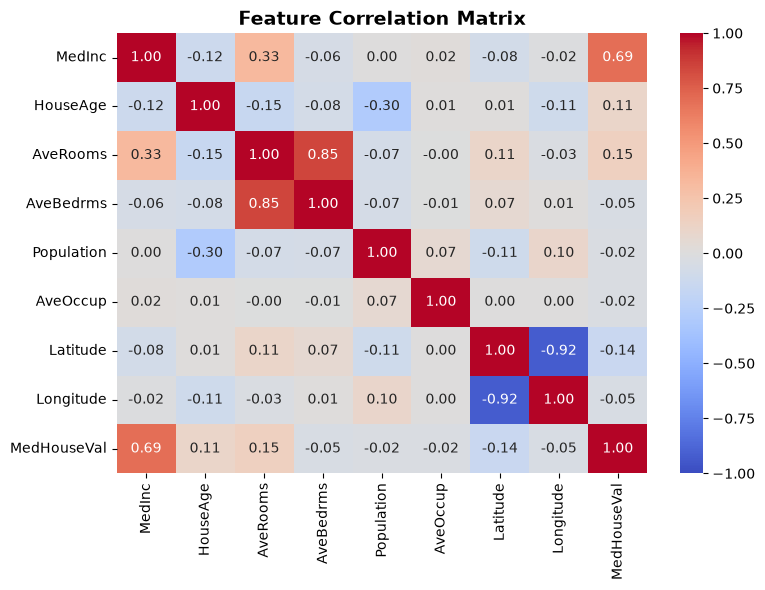

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature Correlation Matrix", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

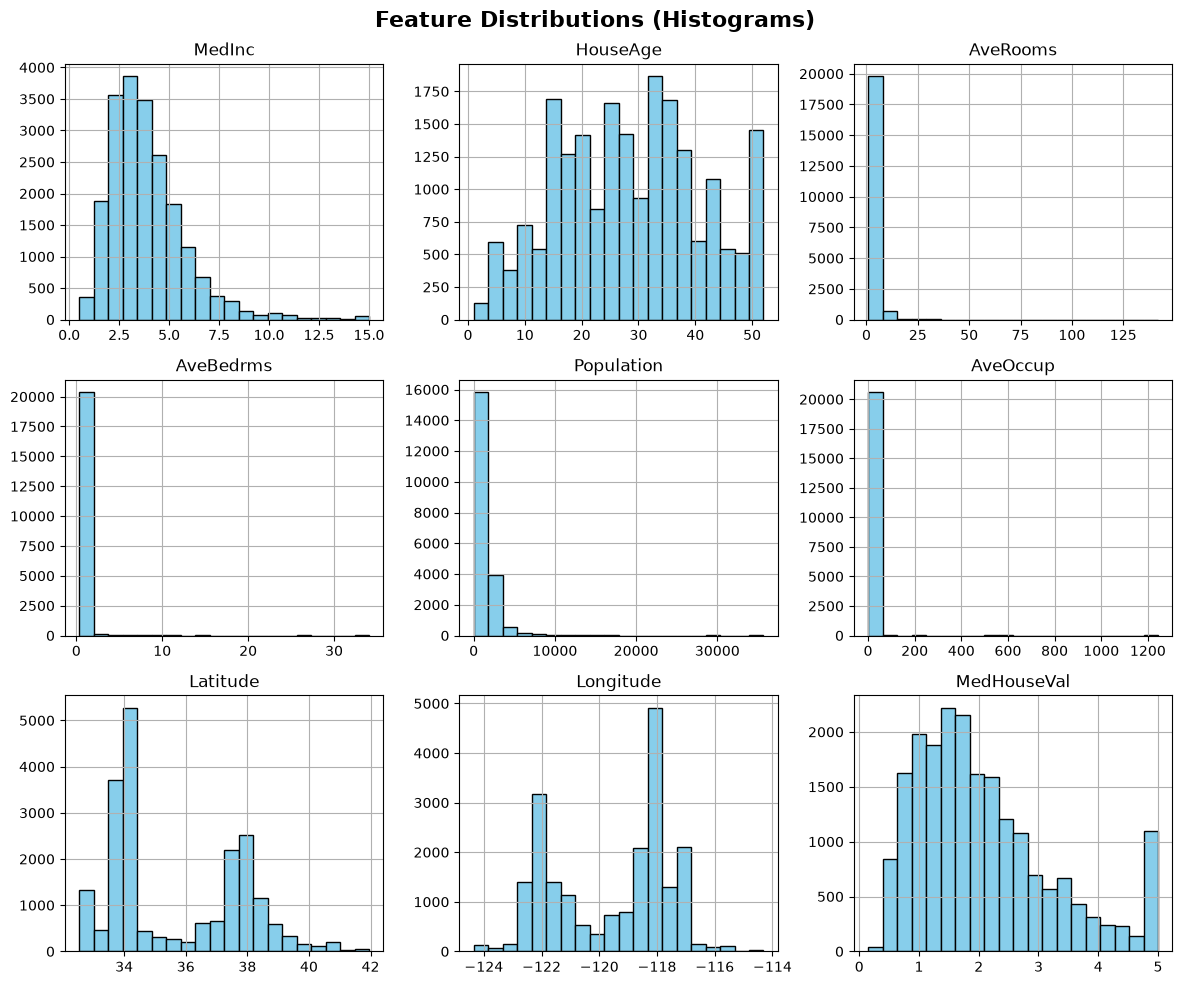

In [8]:
df.hist(bins=20, figsize=(12, 10), color='skyblue', edgecolor='black')
plt.suptitle("Feature Distributions (Histograms)", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

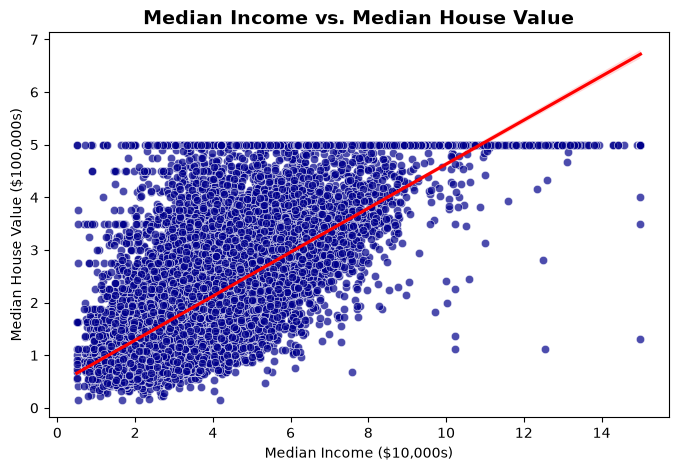

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='MedInc', y='MedHouseVal', alpha=0.7, color='darkblue')
sns.regplot(data=df, x='MedInc', y='MedHouseVal', scatter=False, color='red')
plt.title("Median Income vs. Median House Value", fontsize=14, fontweight="bold")
plt.xlabel("Median Income ($10,000s)")
plt.ylabel("Median House Value ($100,000s)")
plt.show()

### Checking for Outliers using boxplots

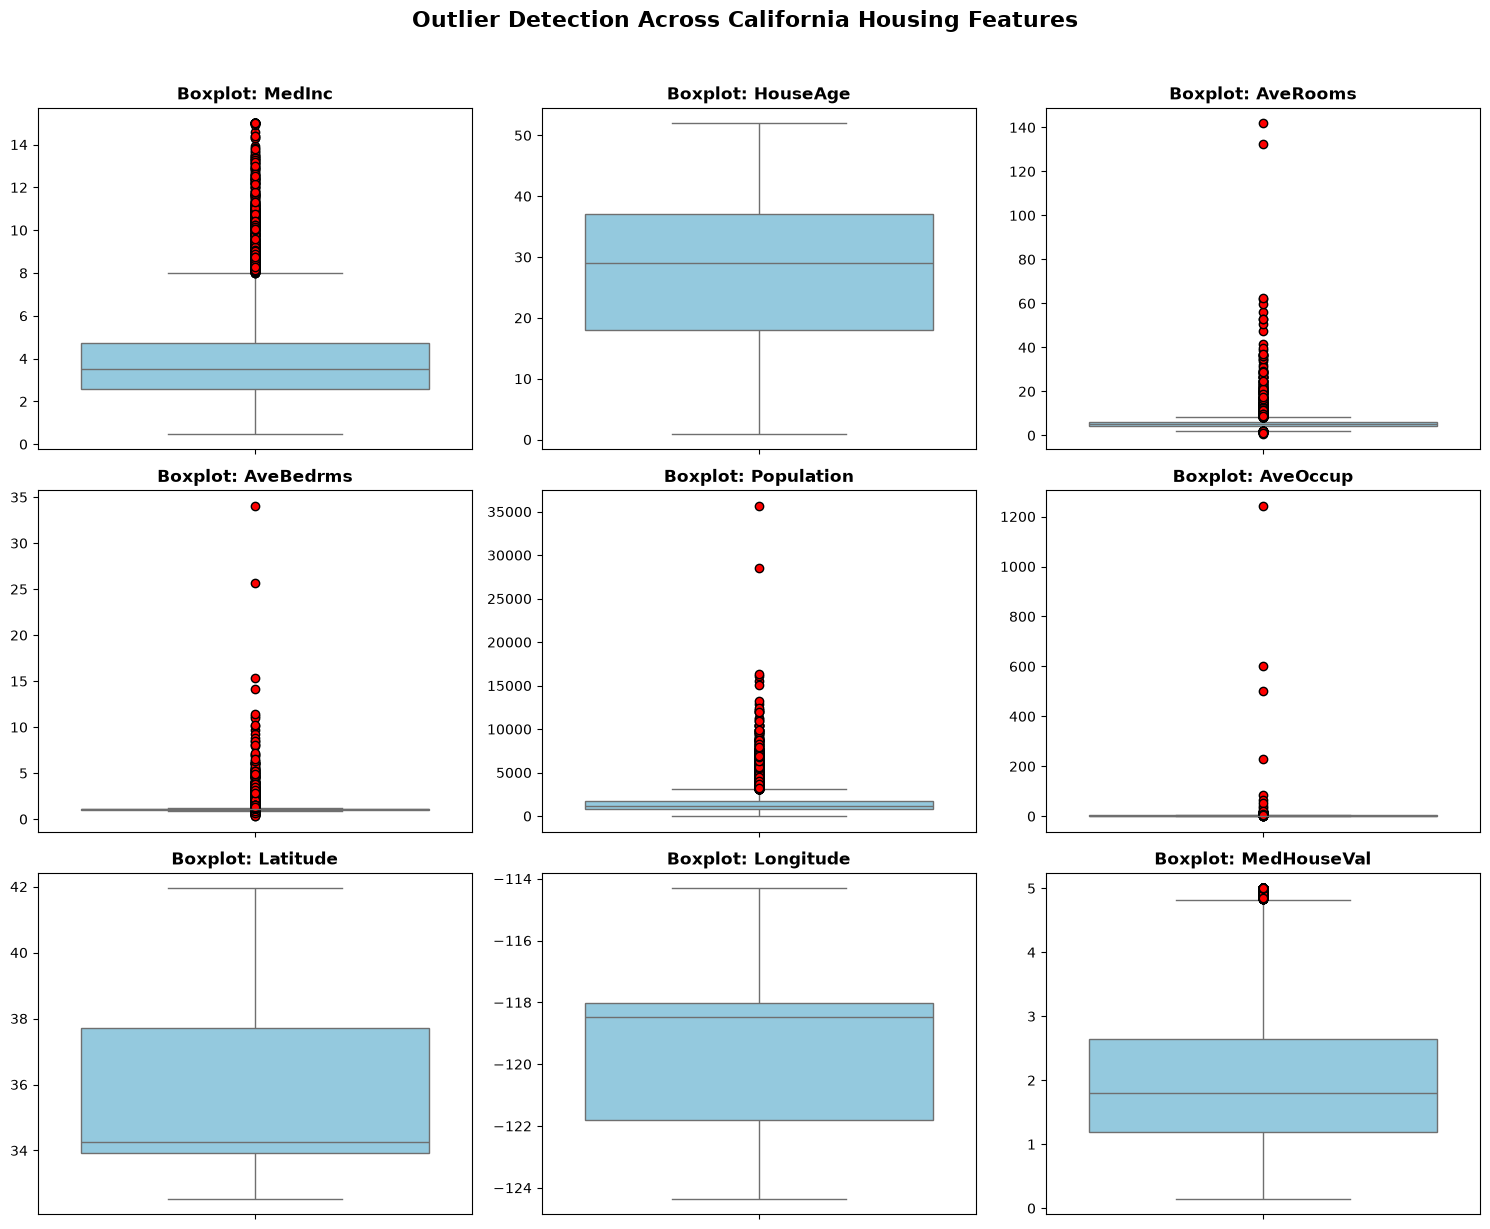

In [10]:
plt.figure(figsize=(15, 12))

for i, col in enumerate(df.columns, 1):
    plt.subplot(3, 3, i)
    # flierprops sets the style for outlier dots (red circles)
    sns.boxplot(
        y=df[col], 
        color='skyblue', 
        flierprops=dict(marker='o', markerfacecolor='red', markeredgecolor='black', markersize=6)
    )
    plt.title(f'Boxplot: {col}', fontweight='bold', fontsize=12)
    plt.ylabel('')

plt.suptitle("Outlier Detection Across California Housing Features", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [11]:
# Function to filter outliers using IQR for a specific column
def filter_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    # Keep only rows within bounds
    filtered_df = df[(df[column] >= lower) & (df[column] <= upper)]
    return filtered_df

for col in df.columns:
    df_clean = filter_outliers_iqr(df, col)

print(f"Original shape: {df.shape}, Cleaned shape: {df_clean.shape}")

Original shape: (20640, 9), Cleaned shape: (19569, 9)


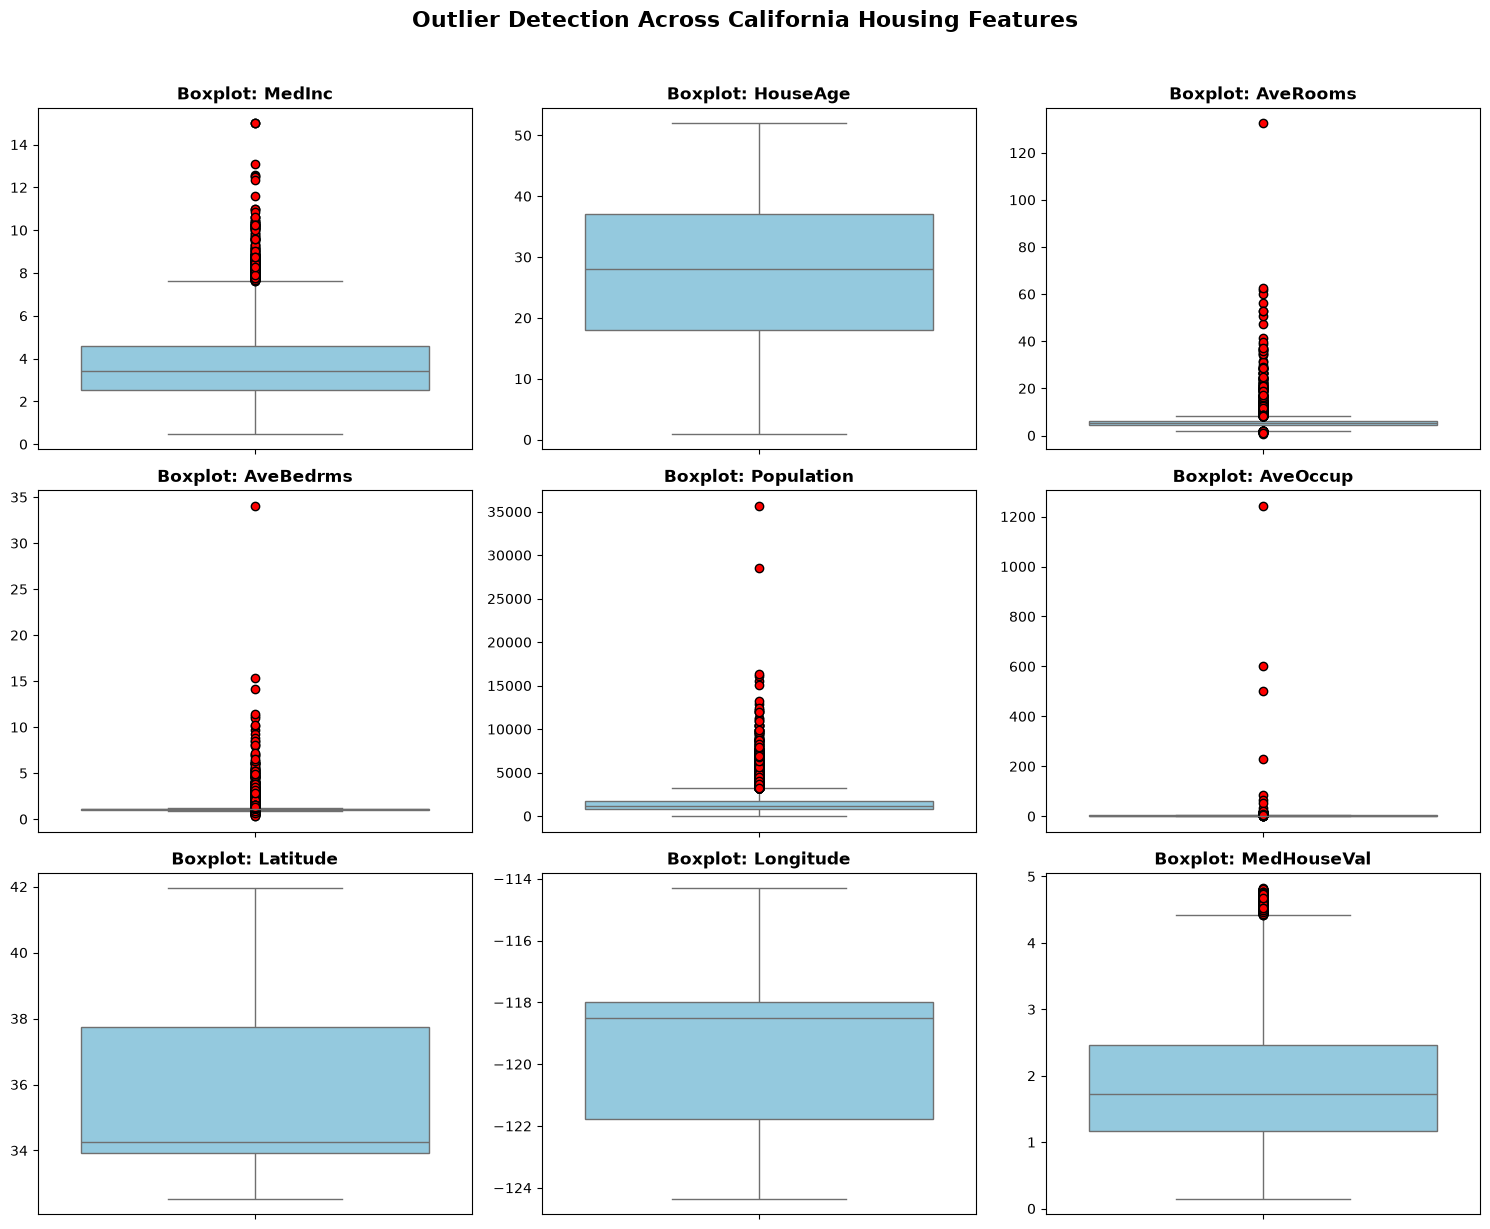

In [12]:
plt.figure(figsize=(15, 12))

for i, col in enumerate(df_clean.columns, 1):
    plt.subplot(3, 3, i)
    # flierprops sets the style for outlier dots (red circles)
    sns.boxplot(
        y=df_clean[col], 
        color='skyblue', 
        flierprops=dict(marker='o', markerfacecolor='red', markeredgecolor='black', markersize=6)
    )
    plt.title(f'Boxplot: {col}', fontweight='bold', fontsize=12)
    plt.ylabel('')

plt.suptitle("Outlier Detection Across California Housing Features", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()